<a class="anchor" id="0"></a>
# **Mubileum Duration Generation with VAE**

<a class="anchor" id="0.1"></a>
# **Table of Contents**

- 1. [Setup](#1)
- 2. [Data Preparation](#2)
<!--     - 2.1 [Data Preparation for LSTM](#2.1) -->
- 3. [EDA](#3)
- 4. [Anomaly Detection](#4)
- 5. [Anomaly Creation](#5)
- 6. [Genetic Algoritm Otimization](#6)


# **1. SetUp** <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [1]:
# Data Manipulation and Analysis
import numpy as np
import pandas as pd

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn for Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

# TensorFlow and Keras for Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Lambda, RepeatVector
from tensorflow.keras import backend as K


from sklearn.metrics import precision_recall_curve

# **2. Data Preparation** <a class="anchor" id="2"></a>

[Table of Contents](#0.1)

In [2]:
# Read a CSV file into a Pandas DataFrame
df = pd.read_csv("/kaggle/input/mobileum/jul_aug_sep_oct_2022_msc_1.csv", sep=";")

# Convert Start Date and Start Hour into a datetime object and set as index
df['TIMESTAMP'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Hour'].astype(str), format='%d/%m/%Y %H')
df.set_index("TIMESTAMP", inplace=True)

# Clean the #Events column, remove any non-numeric characters, fill NaNs with 0, and convert to integer
df['#Events'] = df['#Events'].str.replace(r'[^\d.-]', '', regex=True)
df['#Events'] = df['#Events'].fillna(0)
df['#Events'] = pd.to_numeric(df['#Events']).astype(int)

# Drop unnecessary columns
# df.drop(columns=['Datasource', 'Start Date', 'Start Hour'], inplace=True) 
df.drop(columns=['Datasource', 'Start Date', 'Start Hour', 'Event Duration'], inplace=True)

# Drop duplicates
df.drop_duplicates(inplace=True)

In [3]:
df.head()

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events
TIMESTAMP,,,,,,,
2022-07-18,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105
2022-07-18,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1


In [4]:
df.describe().round()

,#Events
count,145521.0
mean,15305.0
std,78771.0
min,0.0
25%,118.0
50%,806.0
75%,8676.0
max,3053227.0


# **3. EDA** <a class="anchor" id="3"></a>

[Table of Contents](#0.1)

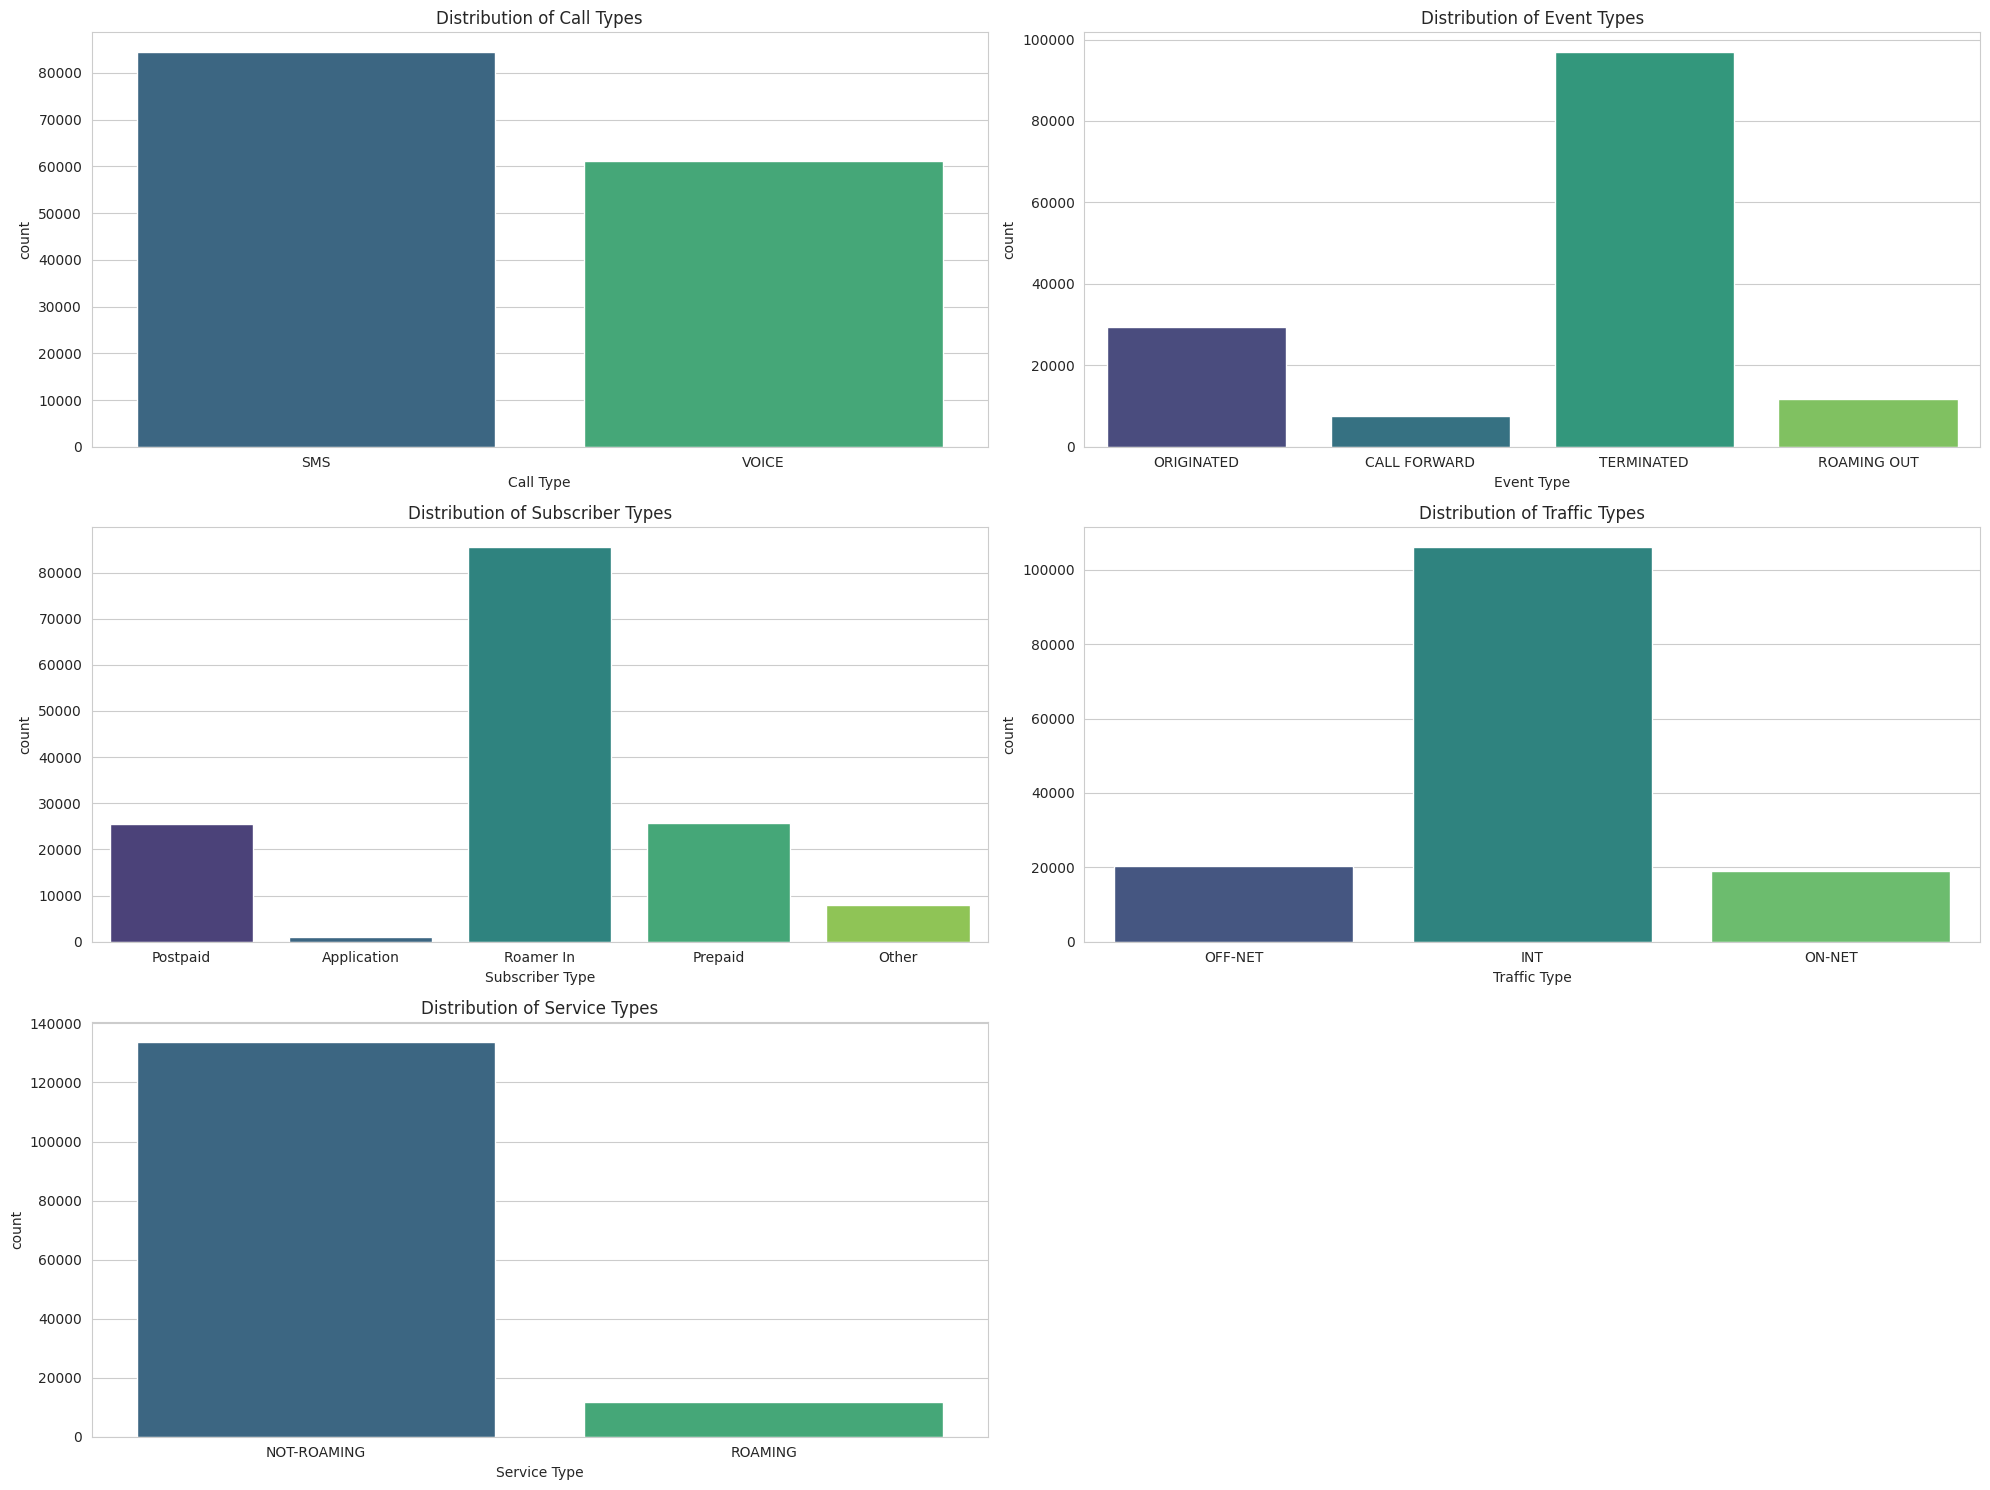

In [5]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Create a figure to hold the subplots
plt.figure(figsize=(20, 15))

# Distribution of Call Types
plt.subplot(3, 2, 1)
sns.countplot(x='Call Type', data=df, palette='viridis')
plt.title('Distribution of Call Types')

# Distribution of Event Types
plt.subplot(3, 2, 2)
sns.countplot(x='Event Type', data=df, palette='viridis')
plt.title('Distribution of Event Types')

# Distribution of Subscriber Types
plt.subplot(3, 2, 3)
sns.countplot(x='Subscriber Type', data=df, palette='viridis')
plt.title('Distribution of Subscriber Types')

# Distribution of Traffic Types
plt.subplot(3, 2, 4)
sns.countplot(x='Traffic Type', data=df, palette='viridis')
plt.title('Distribution of Traffic Types')

# Distribution of Service Types
plt.subplot(3, 2, 5)
sns.countplot(x='Service Type', data=df, palette='viridis')
plt.title('Distribution of Service Types')

# Adjust layout to make room for the titles and prevent overlap
plt.tight_layout()

plt.show()

In [6]:
from ydata_profiling import ProfileReport

/opt/conda/lib/python3.10/site-packages/numba/core/decorators.py:262: NumbaDeprecationWarning: numba.generated_jit is deprecated. Please see the documentation at: https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-generated-jit for more information and advice on a suitable replacement.
  warnings.warn(msg, NumbaDeprecationWarning)
/opt/conda/lib/python3.10/site-packages/visions/backends/shared/nan_handling.py:51: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def hasna(x: np.ndarray) -> bool:


In [7]:
profile = ProfileReport(df.reset_index(), title='Pandas Profiling Report', explorative=True)

# Save the report to an HTML file
profile.to_file('ydata_profiling_report.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# **4. Anomaly Creation** <a class="anchor" id="4"></a>

[Table of Contents](#0.1)

In [8]:
def filter_and_aggregate(df, filter_conditions):
    """
    Filters the DataFrame based on given conditions and aggregates by summing up a specified column.
    
    Args:
    - df: The original DataFrame.
    - filter_conditions: A dictionary where keys are column names and values are the values to filter on.
    
    Returns:
    - A new DataFrame with the filtered and aggregated data.
    """
    # Apply the filter conditions
    df_fil = df.copy()
    for col, val in filter_conditions.items():
        df_fil = df_fil[df_fil[col] == val]
    
    # Drop the columns used for filtering
    df_fil.drop(columns=list(filter_conditions.keys()), inplace=True)
    
    # Group by 'TIMESTAMP' and sum up the '#Events' column
    df_agg = df_fil.groupby('TIMESTAMP')['#Events'].sum().reset_index()
    
    return df_agg


In [9]:
# Define your filter conditions here
filter_conditions = {
    'Call Type': 'SMS',
    'Event Type': 'ORIGINATED'
}

# Now use the function with the DataFrame `df` and the filter conditions.
df_fil = filter_and_aggregate(df, filter_conditions)

# Check the first few rows of the resulting DataFrame
print(df_fil.head())

            TIMESTAMP  #Events
0 2022-07-18 00:00:00     1381
1 2022-07-18 01:00:00      929
2 2022-07-18 02:00:00      705
3 2022-07-18 03:00:00      584
4 2022-07-18 04:00:00      691


<Axes: xlabel='TIMESTAMP'>

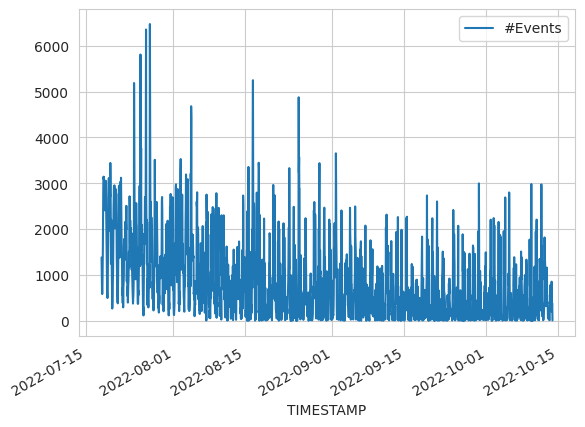

In [10]:
df_fil.plot(x="TIMESTAMP", y="#Events")

<Axes: xlabel='TIMESTAMP'>

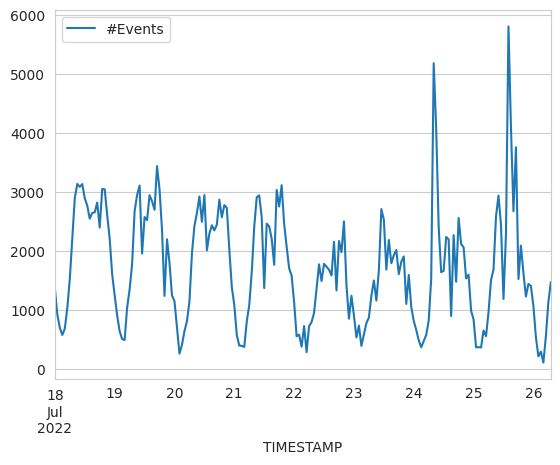

In [11]:
df_fil[:200].plot(x="TIMESTAMP", y="#Events")

In [12]:
def generate_anomaly(mean, std, lower_bound=0):
    """
    Generate a random anomaly value.
    
    Parameters:
    mean (float): The mean value of the normal data.
    std (float): The standard deviation of the normal data.
    lower_bound (int): The minimum value an anomaly can take, inclusive. Default is 0.
    
    Returns:
    int: An anomalous data point.
    """
    upper_normal = mean + 3 * std
    lower_normal = max(mean - 3 * std, lower_bound)
    
    
    # Choose between an anomaly below or above the normal range.
    anomaly_value = np.random.choice([upper_normal, lower_normal])
    return anomaly_value


In [13]:
def insert_anomaly(df_anomaly, index):
    
    start = max(index - 84, 0)
    end = min(index + 83, len(df) - 1)

    std = df_anomaly[start:end]["#Events"].std()
    mean = df_anomaly[start:end]["#Events"].mean()

    anomaly_value = generate_anomaly(mean, std)


    actual_value = df_anomaly.iloc[index]["#Events"]
    df_anomaly.at[df_anomaly.index[index], '#Events'] = anomaly_value
    

#     print(f"Anomaly value: {anomaly_value}")
#     plt.figure(figsize=(10, 6))
#     plt.plot(df.index, df["#Events"], label="Events", marker='o', linestyle='-', markersize=4)
#     plt.scatter(df.index[index], anomaly_value, color='red', s=100, label='Anomaly', zorder=5)
#     plt.xlabel('TIMESTAMP')
#     plt.ylabel('#Events')
#     plt.title('Visualization of #Events with Anomaly Inserted')
#     plt.legend()
#     plt.grid(True)
#     plt.show()
    print( "actual_value: " ,actual_value, "Anomaly_value: ", df_anomaly.iloc[index]["#Events"], "Mean: " , mean, "Std: " , std)
    return mean, std, anomaly_value, actual_value



In [14]:
def insert_nanomaly(df, n_anomalies):
    df_anomaly = df.copy()
    df_anomaly['Anomaly'] = False
    indexes = np.random.choice(range(0, len(df_anomaly)-1), size=n_anomalies, replace=False)
    
    
    for i in indexes:
        insert_anomaly(df_anomaly, i)
    
    df_anomaly["Anomaly"].values[indexes] = True
    
    plt.figure(figsize=(10, 6))
    
    plt.plot(df_anomaly["TIMESTAMP"], df_anomaly["#Events"], label="Events", marker='o', linestyle='-', markersize=4)
    
    plt.scatter(df_anomaly.iloc[indexes]["TIMESTAMP"], df_anomaly["#Events"][indexes], color='red', s=100, label='Anomaly', zorder=5)
    
    plt.xlabel('TIMESTAMP')
    plt.ylabel('#Events')
    plt.title('Visualization of #Events with Anomaly Inserted')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    return df_anomaly

actual_value:  125 Anomaly_value:  0 Mean:  611.3532934131737 Std:  541.7860142853751
actual_value:  2652 Anomaly_value:  0 Mean:  1969.0408163265306 Std:  897.6917699192581
actual_value:  32 Anomaly_value:  2208.726304924544 Mean:  555.7784431137725 Std:  550.9826206035905
actual_value:  36.0 Anomaly_value:  0.0 Mean:  804.6347305389221 Std:  749.4515212086403
actual_value:  215.0 Anomaly_value:  3212.167816379318 Mean:  780.6526946107784 Std:  810.5050405895132
actual_value:  298.0 Anomaly_value:  0.0 Mean:  579.8426724845782 Std:  561.6727289753048
actual_value:  256.0 Anomaly_value:  0.0 Mean:  521.0778443113772 Std:  604.3262104216182
actual_value:  258.0 Anomaly_value:  4130.037098775309 Mean:  1359.3353293413174 Std:  923.5672564779971
actual_value:  480.0 Anomaly_value:  3652.492847831834 Mean:  891.9101796407185 Std:  920.1942227303717
actual_value:  706.0 Anomaly_value:  0.0 Mean:  866.7005988023952 Std:  671.776591834658
actual_value:  1502.0 Anomaly_value:  0.0 Mean:  490.3

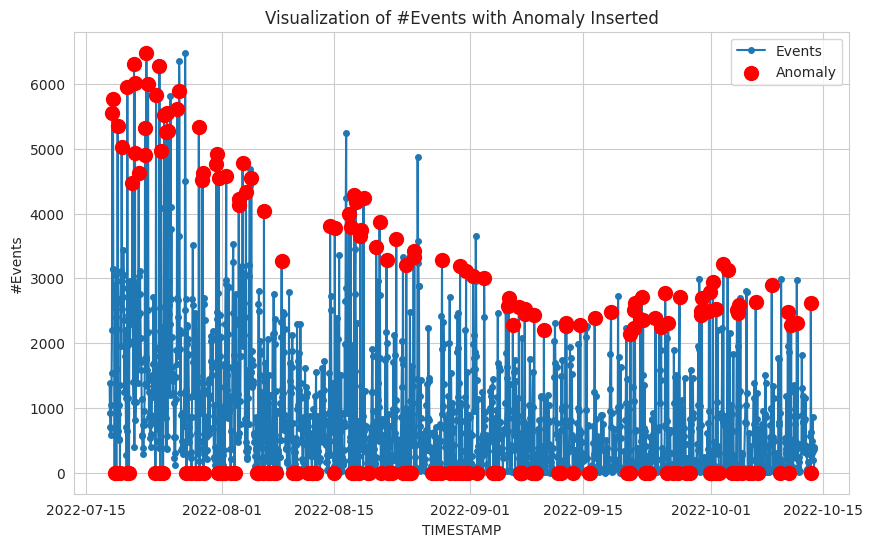

In [15]:
df_anomaly = insert_nanomaly(df_fil, 200)


In [16]:
df_anomaly

,TIMESTAMP,#Events,Anomaly
0,2022-07-18 00:00:00,1381.0,False
1,2022-07-18 01:00:00,929.0,False
2,2022-07-18 02:00:00,705.0,False
3,2022-07-18 03:00:00,584.0,False
4,2022-07-18 04:00:00,691.0,False
...,...,...,...
1905,2022-10-13 17:00:00,854.0,False
1906,2022-10-13 18:00:00,191.0,False
1907,2022-10-13 19:00:00,392.0,False
1908,2022-10-13 20:00:00,370.0,False


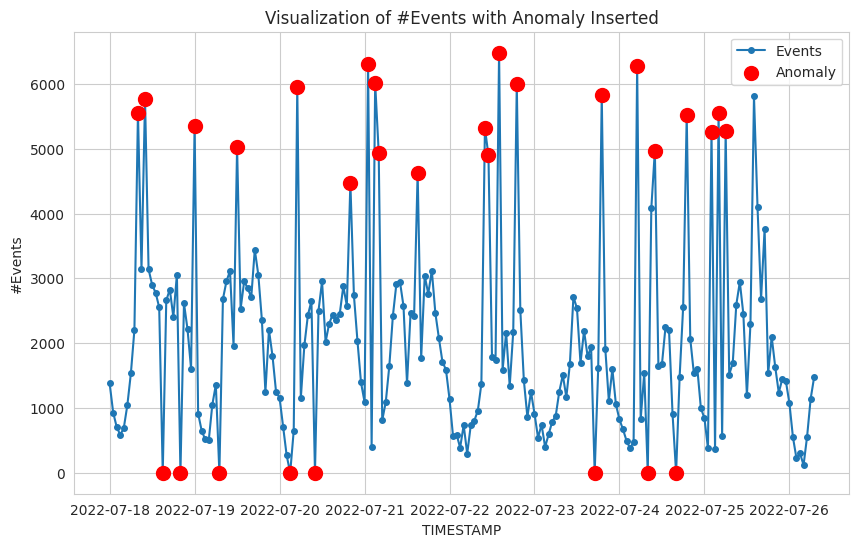

In [17]:
start=0
end=200

aux = df_anomaly[start:end]

indexes = aux[aux["Anomaly"]==True].index
plt.figure(figsize=(10, 6))

plt.plot(aux["TIMESTAMP"], aux["#Events"], label="Events", marker='o', linestyle='-', markersize=4)

# Destacando o valor anômalo
plt.scatter(aux.iloc[(indexes-start).values]["TIMESTAMP"], aux["#Events"][indexes], color='red', s=100, label='Anomaly', zorder=5)

plt.xlabel('TIMESTAMP')
plt.ylabel('#Events')
plt.title('Visualization of #Events with Anomaly Inserted')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
df_anomaly[df_anomaly["Anomaly"].values==True]

,TIMESTAMP,#Events,Anomaly
8,2022-07-18 08:00:00,5558.263895,True
10,2022-07-18 10:00:00,5767.956118,True
15,2022-07-18 15:00:00,0.000000,True
20,2022-07-18 20:00:00,0.000000,True
24,2022-07-19 00:00:00,5355.713011,True
...,...,...,...
1844,2022-10-10 17:00:00,0.000000,True
1851,2022-10-11 00:00:00,2284.751122,True
1868,2022-10-11 19:00:00,2306.526042,True
1898,2022-10-13 10:00:00,0.000000,True


Choice one to be the target the anomaly for desaggregated df

## 4.1 Insert the anomaly into desaggregated df

In [19]:
anomaly_choiced = df_anomaly[df_anomaly["Anomaly"].values==True].iloc[0]

In [20]:
anomaly_choiced["TIMESTAMP"]

Timestamp('2022-07-18 08:00:00')

In [21]:
df_modified = df.copy()
# Sexta feira as 16h
df_modified.loc['2022-07-22 16:00:00', '#Events']= round(df_modified.loc['2022-07-22 16:00:00', '#Events'] * 30 / 70)

In [22]:
print("(modified, original)")
(df_modified.loc['2022-07-22 16:00:00', '#Events'].sum(), df.loc['2022-07-22 16:00:00', '#Events'].sum())

(modified, original)


(490591, 1144723)

In [23]:
# Define your filter conditions here
filter_conditions1 = {
    'Call Type': 'SMS'
}

filter_conditions2 = {
    'Call Type': 'SMS',
    'Service Type': 'ROAMING',
    'Event Type': 'TERMINATED',
}


filter_conditions3 = {
    'Call Type': 'VOICE',
    'Service Type': 'ROAMING',
}

In [24]:
original_agg1 = filter_and_aggregate(df, filter_conditions1)
modified_agg1 = filter_and_aggregate(df_modified, filter_conditions1)
original_agg2 = filter_and_aggregate(df, filter_conditions2)
modified_agg2 = filter_and_aggregate(df_modified, filter_conditions2)
original_agg3 = filter_and_aggregate(df, filter_conditions3)
modified_agg3 = filter_and_aggregate(df_modified, filter_conditions3)

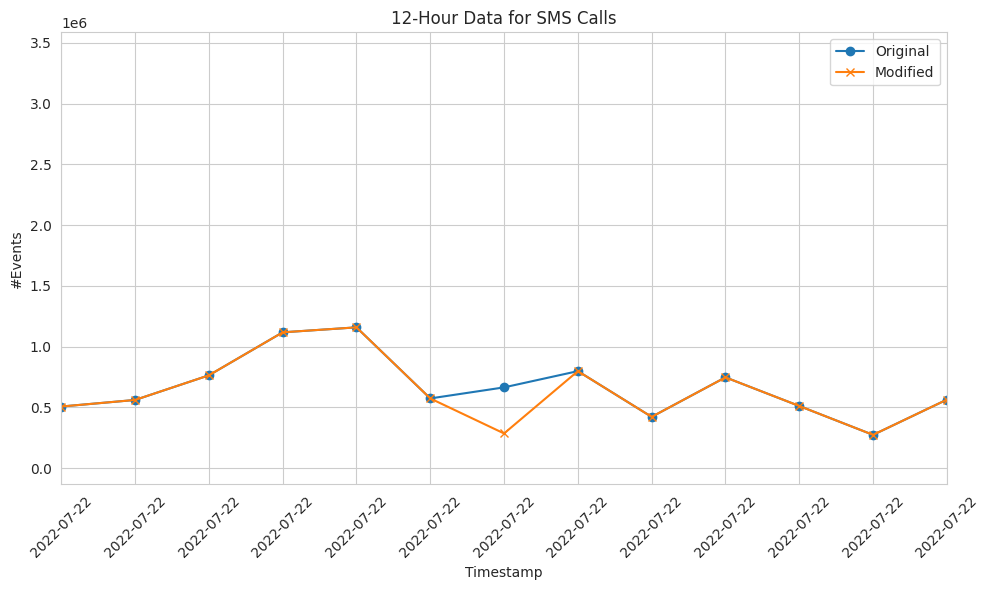

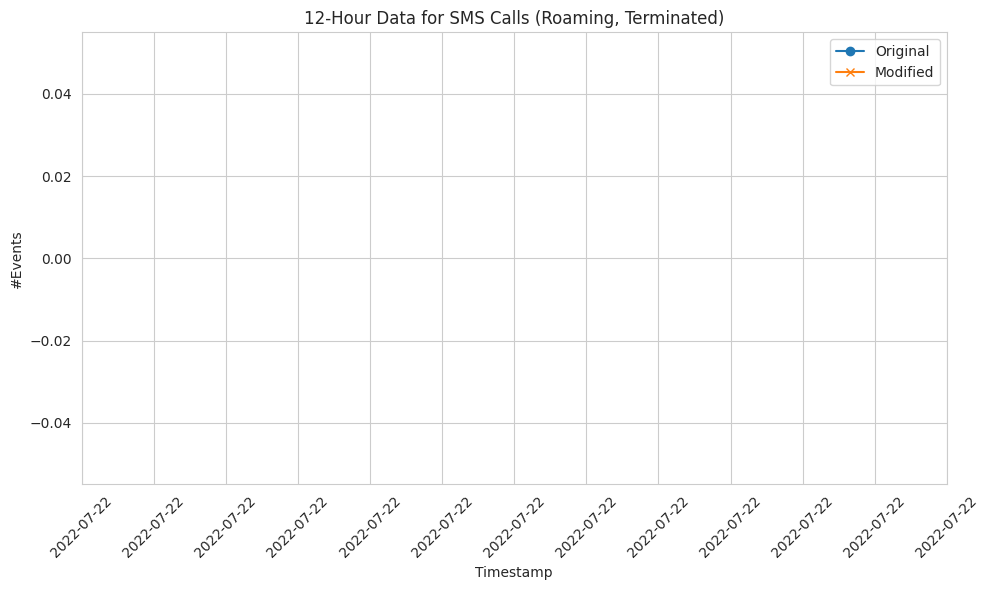

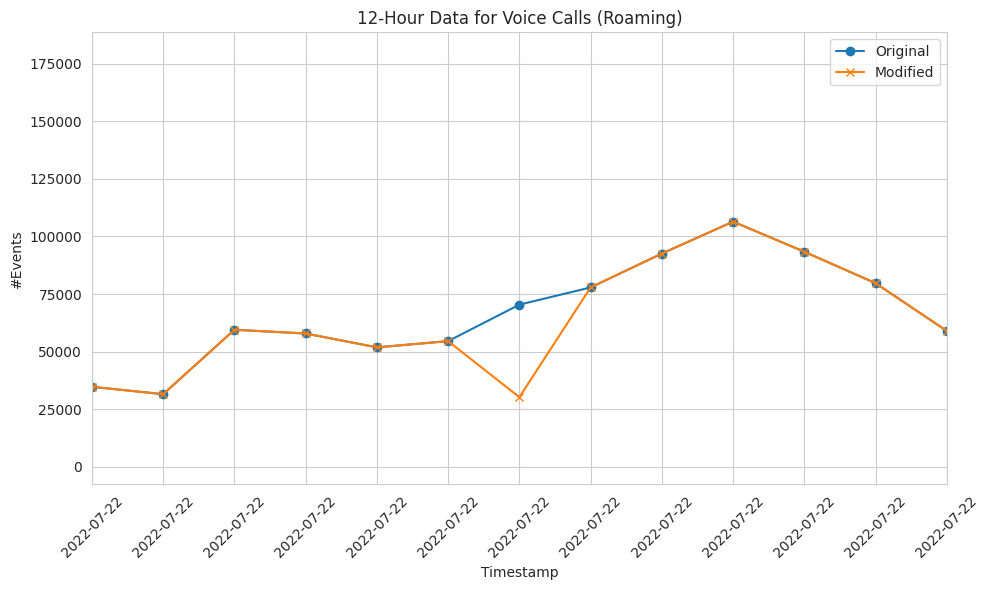

In [25]:
center_timestamp = pd.Timestamp('2022-07-22 16:00:00')
half_day = pd.Timedelta(hours=12)
start_time_half_day = center_timestamp - half_day / 2
end_time_half_day = center_timestamp + half_day / 2

# Function to plot the data with exact axis limits for 12-hour range
def plot_data_exact_12h(df_original, df_modified, title):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(df_original['TIMESTAMP'], df_original['#Events'], label='Original', marker='o')
    ax.plot(df_modified['TIMESTAMP'], df_modified['#Events'], label='Modified', marker='x')
    ax.set_title(title)
    ax.set_xlabel('Timestamp')
    ax.set_ylabel('#Events')
    ax.legend()
    ax.set_xlim(start_time_half_day, end_time_half_day)  # Set exact 12-hour range
    plt.xticks(pd.date_range(start=start_time_half_day, end=end_time_half_day, freq='H'), rotation=45)
    plt.grid(True)
    plt.tight_layout()

# Replotting the data for exact 12-hour window
plot_data_exact_12h(original_agg1, modified_agg1, '12-Hour Data for SMS Calls')
plot_data_exact_12h(original_agg2, modified_agg2, '12-Hour Data for SMS Calls (Roaming, Terminated)')
plot_data_exact_12h(original_agg3, modified_agg3, '12-Hour Data for Voice Calls (Roaming)')


1. Definir o nivel de agregacao
    Escolher uma categoria
    Escolher um ponto aleatorio
    tirar a media /std da vizinhanca w=168 
    rescrever o valor original +- 3 std max(0, -x)
    

Injetar anomalias de forma global/local
nova coluna / hora
nivel mais fino
desvio padrao de vizinhaca antes e depois 


Anomalias pontuais usando a estatistica de vizinhanca ()
Distribuicao gaussiana

Global/localizada - dataset sintetico
Gramatical evolution
python

VAE (Tensorflow) Ex: Desvio padrão modulo de 3

# 5. Hierarchical Structure

In [26]:
def hierarchical_filter_and_aggregate(df, hierarchy):
    """
    Filters and aggregates the DataFrame based on a hierarchical structure of conditions.

    Args:
    - df: The original DataFrame.
    - hierarchy: A list of dictionaries representing the hierarchy of filters. Each dictionary
      contains 'column' and 'value' keys, and optionally a 'children' key with a list of
      dictionaries representing the next level of the hierarchy.

    Returns:
    - A dictionary with the aggregated data and the hierarchical structure.
    """
    if not hierarchy:
        # Base case: return the sum of the #Events column
        return df['#Events'].sum()

    # Get the current level's filter conditions
    current_level = hierarchy[0]
    column = current_level['column']
    children = current_level.get('children', [])

    # Create a dictionary to hold the results of this level
    result = {}

    # If the value is specified, filter and then recurse into the children
    if 'value' in current_level:
        filtered_df = df[df[column] == current_level['value']]
        result[current_level['value']] = hierarchical_filter_and_aggregate(filtered_df, children)
    else:
        # If no value is specified, iterate over the unique values in the column
        for value in df[column].unique():
            filtered_df = df[df[column] == value]
            result[value] = hierarchical_filter_and_aggregate(filtered_df, children)

    return result

In [27]:
print(df['Service Type'].unique())
print(df['Call Type'].unique())
print(df['Event Type'].unique())

['NOT-ROAMING' 'ROAMING']
['SMS' 'VOICE']
['ORIGINATED' 'CALL FORWARD' 'TERMINATED' 'ROAMING OUT']


In [28]:
df

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events
TIMESTAMP,,,,,,,
2022-07-18 00:00:00,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105
2022-07-18 00:00:00,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16
2022-07-18 00:00:00,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7
2022-07-18 00:00:00,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15
2022-07-18 00:00:00,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1
...,...,...,...,...,...,...,...
2022-10-13 21:00:00,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0042,209
2022-10-13 21:00:00,SMS,TERMINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,3748
2022-10-13 21:00:00,SMS,TERMINATED,Prepaid,INT,NOT-ROAMING,P_0001,11801


In [29]:
filter_and_aggregate(df, {'Call Type': 'SMS', 'Subscriber Type': 'Roamer In'})

,TIMESTAMP,#Events
0,2022-07-18 00:00:00,29956
1,2022-07-18 01:00:00,18840
2,2022-07-18 02:00:00,19181
3,2022-07-18 03:00:00,14678
4,2022-07-18 04:00:00,35893
...,...,...
2105,2022-10-13 17:00:00,64902
2106,2022-10-13 18:00:00,45146
2107,2022-10-13 19:00:00,54874
2108,2022-10-13 20:00:00,37962


In [30]:
# Define the filter conditions for each leaf in the hierarchy
filter_conditions_leaves = [
    {'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING', 'Event Type': 'TERMINATED'},
    {'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING', 'Event Type': 'ORIGINATED'},
    {'Call Type': 'SMS', 'Subscriber Type': 'Roamer In'}
]

# Use the function filter_and_aggregate to aggregate for every leaf and store the dataframes
aggregated_dataframes = {}

for i, conditions in enumerate(filter_conditions_leaves, start=1):
    agg_df = filter_and_aggregate(df, conditions)
    aggregated_dataframes[f'leaf_{i}'] = agg_df

# Let's output the keys of the aggregated_dataframes dictionary to confirm the storage
aggregated_dataframes.keys()

dict_keys(['leaf_1', 'leaf_2', 'leaf_3'])

In [31]:
aggregated_dataframes

{'leaf_1':                TIMESTAMP  #Events
 0    2022-07-18 00:00:00   383772
 1    2022-07-18 01:00:00   105980
 2    2022-07-18 02:00:00    92563
 3    2022-07-18 03:00:00    96383
 4    2022-07-18 04:00:00   173491
 ...                  ...      ...
 2105 2022-10-13 17:00:00   867756
 2106 2022-10-13 18:00:00   545487
 2107 2022-10-13 19:00:00   464669
 2108 2022-10-13 20:00:00   928911
 2109 2022-10-13 21:00:00   217145
 
 [2110 rows x 2 columns],
 'leaf_2':                TIMESTAMP  #Events
 0    2022-07-18 00:00:00     1381
 1    2022-07-18 01:00:00      929
 2    2022-07-18 02:00:00      705
 3    2022-07-18 03:00:00      584
 4    2022-07-18 04:00:00      691
 ...                  ...      ...
 1905 2022-10-13 17:00:00      854
 1906 2022-10-13 18:00:00      191
 1907 2022-10-13 19:00:00      392
 1908 2022-10-13 20:00:00      370
 1909 2022-10-13 21:00:00        9
 
 [1910 rows x 2 columns],
 'leaf_3':                TIMESTAMP  #Events
 0    2022-07-18 00:00:00    29956
 1  

In [32]:
aggregated_dataframes['leaf_1']

,TIMESTAMP,#Events
0,2022-07-18 00:00:00,383772
1,2022-07-18 01:00:00,105980
2,2022-07-18 02:00:00,92563
3,2022-07-18 03:00:00,96383
4,2022-07-18 04:00:00,173491
...,...,...
2105,2022-10-13 17:00:00,867756
2106,2022-10-13 18:00:00,545487
2107,2022-10-13 19:00:00,464669
2108,2022-10-13 20:00:00,928911


In [33]:
hierarchy = [
    {
        'column': 'Call Type',
        'value': 'SMS',
        'children': [
            {
                'column': 'Service Type',
                'children': [
                    {
                        'column': 'Event Type',
                        'value': 'TERMINATED'
                    },
                    {
                        'column': 'Event Type',
                        'value': 'ORIGINATED'
                    }
                ]
            }
        ]
    }
]


In [34]:
print(df['Service Type'].unique())
print(df['Call Type'].unique())
print(df['Event Type'].unique())

['NOT-ROAMING' 'ROAMING']
['SMS' 'VOICE']
['ORIGINATED' 'CALL FORWARD' 'TERMINATED' 'ROAMING OUT']


In [35]:
df.head()

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events
TIMESTAMP,,,,,,,
2022-07-18,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105
2022-07-18,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1


# **5. Anomaly Detetion** <a class="anchor" id="5"></a>

[Table of Contents](#0.1)

1. label das anomalias
2. hierarquia fixa, calcular Matrix P
3. Optimizacao S

Como a Criacao de janelas series temporais relaciona-se com o seguintes:
Hierarquias
Detecao de anomalias
agoritmos genericos

Matrix Profile
Mais tarde: Pyod (outlier detection)

Distancia minima
AUC (‘threshold’)

## Ao aumentar o quartile a anomalia restringe aos valores dos eventos com duracao excessiva, apesar da duranca aumentar com o tempo seguindo uma periodicidade semanal

verificar as anomalias serem iguais entre os dois colunas ja que tem o mesmo numero de anomalias do Event Duration and #Events

## 5.1 Statistical Thresholding

In [36]:
# Calculate mean and standard deviation of the "#Events" column
mean_events = df_anomaly['#Events'].mean()
std_events = df_anomaly['#Events'].std()

# Define thresholds for anomalies
upper_threshold = mean_events + 3 * std_events
lower_threshold = mean_events - 3 * std_events

# Identify anomalies
df_anomaly_stat = df_anomaly.copy()
df_anomaly_stat['Detected_Anomaly'] = (df_anomaly_stat['#Events'] - mean_events)/ std_events
print(df_anomaly_stat['Detected_Anomaly'] )
# Count the detected anomalies and display the rows with anomalies
anomaly_count = df_anomaly_stat['Detected_Anomaly'].sum()
# anomaly_data = df_anomaly_stat[df_anomaly_stat['Detected_Anomaly']]

# anomaly_count, anomaly_data.head()


0       0.365510
1      -0.045422
2      -0.249070
3      -0.359076
4      -0.261798
          ...   
1905   -0.113608
1906   -0.716369
1907   -0.533632
1908   -0.553633
1909   -0.881833
Name: Detected_Anomaly, Length: 1910, dtype: float64


In [37]:
from sklearn.metrics import roc_auc_score, roc_curve

In [38]:
auc_score = roc_auc_score(df_anomaly_stat['Anomaly'], df_anomaly_stat['Detected_Anomaly'])

In [39]:
fpr, tpr, thresholds = roc_curve(df_anomaly_stat['Anomaly'], df_anomaly_stat['Detected_Anomaly'])

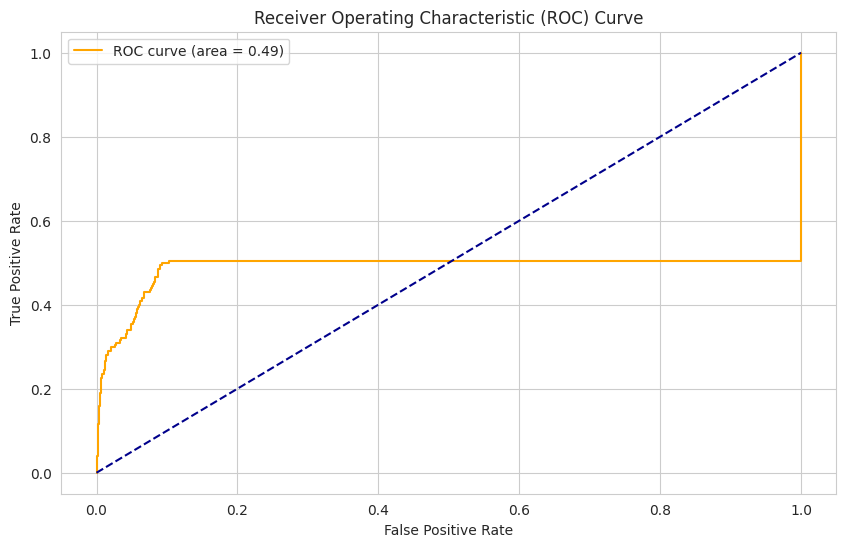

In [40]:
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='orange', label=f'ROC curve (area = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='darkblue', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid(True)
plt.show()

## 4.2 seasonal decomposition method 

In [41]:
df_anomaly_stat

,TIMESTAMP,#Events,Anomaly,Detected_Anomaly
0,2022-07-18 00:00:00,1381.0,False,0.365510
1,2022-07-18 01:00:00,929.0,False,-0.045422
2,2022-07-18 02:00:00,705.0,False,-0.249070
3,2022-07-18 03:00:00,584.0,False,-0.359076
4,2022-07-18 04:00:00,691.0,False,-0.261798
...,...,...,...,...
1905,2022-10-13 17:00:00,854.0,False,-0.113608
1906,2022-10-13 18:00:00,191.0,False,-0.716369
1907,2022-10-13 19:00:00,392.0,False,-0.533632
1908,2022-10-13 20:00:00,370.0,False,-0.553633


In [42]:
df_anomaly_stat.to_csv("anomaly.csv", index=False)

In [43]:
from sklearn.metrics import confusion_matrix

# Labels are the 'Anomaly' column from the dataset
y = df_anomaly_stat['Anomaly']

# Predictions from statistical thresholding
y_pred = df_anomaly_stat['Detected_Anomaly']

cm = confusion_matrix(y, y_pred)
cm

ValueError: Classification metrics can't handle a mix of binary and continuous targets

In [ ]:
from sklearn.metrics import f1_score

f1_score(y, y_pred)

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

df_anomaly_decomp = df_anomaly.copy()

decomposition = seasonal_decompose(df_anomaly_decomp['#Events'], model='additive', period=24)
df_anomaly_decomp['Residual'] = decomposition.resid  # Extract the residual component

# Fill NaN values in 'Residual' to handle edges of the series
df_anomaly_decomp['Residual'].fillna(0, inplace=True)

# Use the absolute value of the residuals as continuous scores
df_anomaly_decomp['Continuous_Score'] = abs(df_anomaly_decomp['Residual'])

# Extract the labels for anomalies
labels = df_anomaly_decomp['Anomaly']

# Calculate precision, recall, and thresholds for these scores
precision, recall, thresholds = precision_recall_curve(labels, df_anomaly_decomp['Continuous_Score'])

# Plotting the precision-recall curve
fig, ax = plt.subplots()
ax.plot(recall, precision, marker='.', label='Precision-Recall Curve')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve using Seasonal Decomposition Residuals')
ax.legend()
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# # Example data preparation
# df_anomaly_LR = df_anomaly.copy()

# df_anomaly_LR['Lagged_1'] = df_anomaly_LR['#Events'].shift(1)
# df_anomaly_LR['Rolling_Mean'] = df_anomaly_LR['#Events'].rolling(window=24).mean()
# df_anomaly_LR.dropna(inplace=True)  # Drop rows with NaN values

# # Feature matrix and target array
# X = df_anomaly_LR[['Lagged_1', 'Rolling_Mean']]
# y = df_anomaly_LR['Anomaly'].astype(int)

# # Splitting the data
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # Logistic Regression model
# model = LogisticRegression()
# model.fit(X_train, y_train)

# # Predicting probabilities
# probabilities = model.predict_proba(X_test)[:, 1]

# # Evaluate model
# print(classification_report(y_test, model.predict(X_test)))

# # Additional steps could include plotting the precision-recall curve


In [ ]:
y.values

In [ ]:
df_anomaly[df_anomaly["Anomaly"]==True]

In [ ]:
X = df_anomaly.iloc[:, 1:2].values
y = df_anomaly.iloc[:, 2:3].values.reshape(-1,)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

# Prevê as probabilidades para os dados de teste
# As probabilidades para a classe de interesse (tipicamente classe 1 para casos positivos) ficam na segunda coluna
probabilities = model.predict_proba(X_test)[:, 1]

# Calcula AUC para a curva ROC usando as probabilidades previstas e os verdadeiros rótulos de teste
auc_roc = roc_auc_score(y_test, probabilities)

In [ ]:
y_test.size

In [ ]:
predictions = model.predict(X_test)

# Calcula a matriz de confusão
cm = confusion_matrix(y_test, predictions)

# Visualiza a matriz de confusão
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
from sklearn.ensemble import IsolationForest

X = df_anomaly.iloc[:, 1:2].values
y = df_anomaly.iloc[:, 2:3].values.reshape(-1,)
clf = IsolationForest(random_state=42, contamination='auto')  
clf.fit(X)


In [ ]:
# As previsões do Isolation Forest são -1 para anomalias e 1 para normais
predictions = clf.predict(X)
# Para calculo do ROC, nós precisamos de pontuações de decisão ou probabilidades
# O Isolation Forest fornece uma pontuação de anomalia que podemos utilizar
scores = clf.decision_function(X)


In [ ]:

binary_predictions = (predictions == 1).astype(int)


In [ ]:
from sklearn.metrics import confusion_matrix


cm = confusion_matrix(y, binary_predictions)

# Visualização da matriz de confusão
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
from sklearn.metrics import roc_curve, auc


fpr, tpr, thresholds = roc_curve(y, -scores)

# Calcular AUC
roc_auc = auc(fpr, tpr)


plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:0.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


# **6. Genetic Algoritm Optimization** <a class="anchor" id="6"></a>

[Table of Contents](#0.1)

As hierarquias so entram aqui nesta fase?
as anomalias agregam, so basta ter um dos valores da juncao positiva para ser anomalia

Amostragem aleatória das hierarquias
Definir população inicial
Como fazer as mutações

Genetic Programing

Ex: 
 > Comocar com 100 aleatorias e avaliamos o fitness (F1 score)
 > > 100 hieraquias aleatorias
 > Escolher as 20 melhores e fazer multacoes ate termos uma nova populacao de 100 
 > Paragem:
 > > O melhor F1 score da populacao nao aumenta mais que 1%
 > >


In [ ]:
df